# Discrete CQL trained on tree dataset

This notebook loads the CQL test trajectories and plots, per query, the cumulative trajectory cost versus the overall NDCG improvement. Overlapping points are sized and labeled by the number of queries they represent.

In [4]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

RESULTS_PATH = Path("results/trajectories_cql_test_results_dev_50.csv")
df = pd.read_csv(RESULTS_PATH)
df.head()

,query_id,query,new_query,action_name,query_length,score_spread,score_entropy,step,rank_overlap,query_drift,...,ndcg_after,recall_before,recall_after,cost,latency_ms,cumulative_cost,cumulative_latency_ms,reward,terminal,timeout
0,1049368,who s sherlock holmes,who s sherlock holmes conan,PseudoRelevanceFeedback,4.0,0.692715,3.604299,1,0.588235,0.140968,...,0.000000,0.0,0.0,0.3,1310.185909,0.3,1310.185909,-0.103673,0,0
1,1049368,who s sherlock holmes,Sherlock Holmes is a fictional detective creat...,QueryReform,5.0,0.007163,3.911997,2,0.084746,0.227414,...,0.386853,0.0,1.0,1.0,26169.304609,1.3,27479.490519,0.201395,0,0
2,1049368,who s sherlock holmes,Sherlock Holmes is a fictional detective creat...,STOP,83.0,17.149378,0.567290,3,1.000000,0.227414,...,0.386853,1.0,1.0,0.0,0.000000,1.3,27479.490519,0.000000,1,0
3,262974,how long is a typical car loan?,how long is a typical car loan?,STOP,7.0,0.985524,3.012414,1,1.000000,0.000000,...,0.000000,0.0,0.0,0.0,0.000000,0.0,0.000000,0.000000,1,0
4,811852,what is the common name for jade,what is the common name for jade,STOP,7.0,1.402513,1.909746,1,1.000000,0.000000,...,0.000000,0.0,0.0,0.0,0.000000,0.0,0.000000,0.000000,1,0


In [5]:
# Aggregate one point per query: final cumulative cost and overall NDCG improvement
grouped = df.groupby("query_id")
per_query = pd.DataFrame({
    "cumulative_cost": grouped["cumulative_cost"].max(),
    "ndcg_improvement": grouped.apply(lambda g: g["ndcg_after"].iloc[-1] - g["ndcg_before"].iloc[0]),
}).reset_index()

print("Queries:", len(per_query))
print("Negative improvements:", (per_query["ndcg_improvement"] < 0).sum())
per_query.head()

Queries: 50
Negative improvements: 0


,query_id,cumulative_cost,ndcg_improvement
0,2,0.0,0.000000
1,1288,1.3,0.569323
2,1576,0.0,0.000000
3,2235,0.0,0.000000
4,262232,0.0,0.000000


In [6]:
# Count how many queries fall on each exact (improvement, cost) point
point_counts = per_query.groupby(["ndcg_improvement", "cumulative_cost"]).size().reset_index(name="n_queries")
point_counts = point_counts.sort_values("n_queries", ascending=False).reset_index(drop=True)
point_counts.head()

,ndcg_improvement,cumulative_cost,n_queries
0,0.000000,0.0,33
1,0.369070,0.3,2
2,0.059619,1.3,1
3,0.270238,1.0,1
4,0.244651,1.6,1


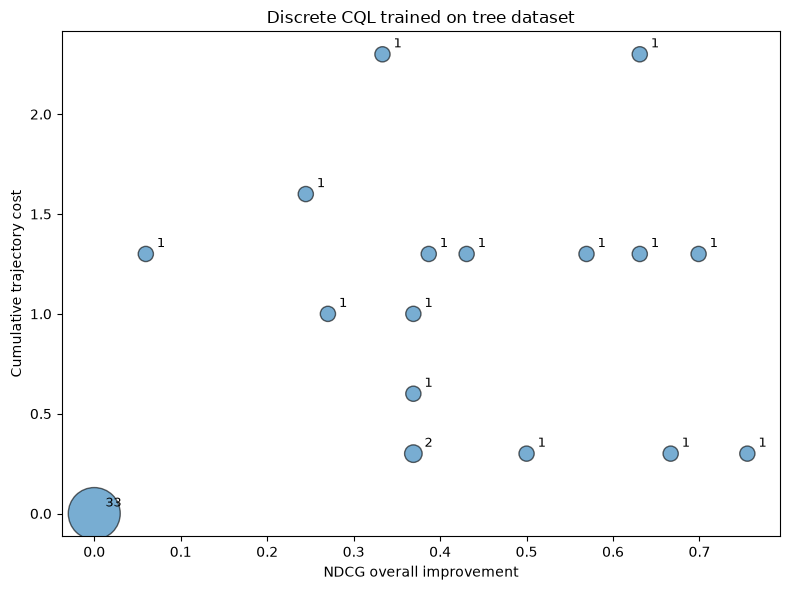

In [7]:
fig, ax = plt.subplots(figsize=(8, 6))

# Size by query count, with a small base size so singletons are still visible
sizes = 80 + 40 * point_counts["n_queries"]
scatter = ax.scatter(
    point_counts["ndcg_improvement"],
    point_counts["cumulative_cost"],
    s=sizes,
    alpha=0.6,
    edgecolors="black",
)

# Label each point with its query count
for _, row in point_counts.iterrows():
    ax.annotate(
        str(int(row["n_queries"])),
        (row["ndcg_improvement"], row["cumulative_cost"]),
        textcoords="offset points",
        xytext=(8, 5),
        fontsize=9,
    )

ax.set_xlabel("NDCG overall improvement")
ax.set_ylabel("Cumulative trajectory cost")
ax.set_title("Discrete CQL trained on tree dataset")
plt.tight_layout()
plt.show()